# Practical 07 – Logistic Regression and KNN Combined

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report


In [8]:
raw = load_breast_cancer(as_frame=True)
X = raw.data
y = raw.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [9]:
def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    scores = {'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, pos_label=0), 'Recall': recall_score(y_test, pred, pos_label=0), 'F1': f1_score(y_test, pred, pos_label=0)}
    print(name, scores)
    print(classification_report(y_test, pred, target_names=['Malignant', 'Benign']))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1], display_labels=['Malignant', 'Benign'], cmap='Blues')
    plt.title(name)
    plt.show()
    return scores


Logistic Regression {'Accuracy': 0.9824561403508771, 'Precision': 0.9761904761904762, 'Recall': 0.9761904761904762, 'F1': 0.9761904761904762}
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



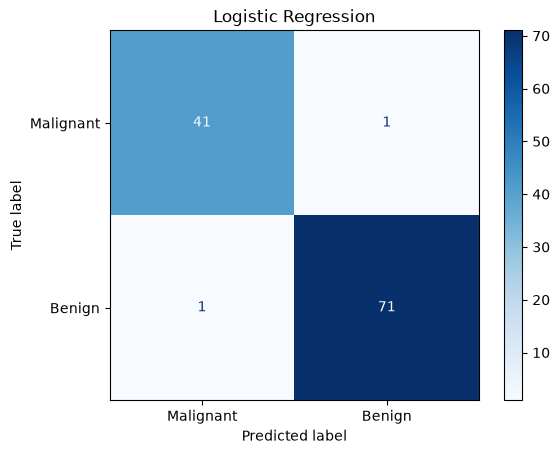

C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds

KNN {'Accuracy': 0.956140350877193, 'Precision': 0.9512195121951219, 'Recall': 0.9285714285714286, 'F1': 0.9397590361445783}
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



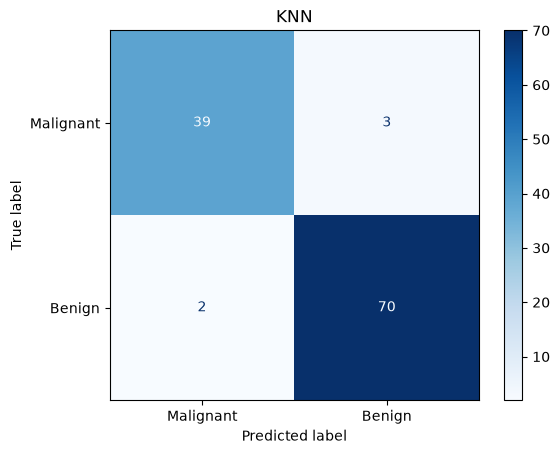

                     Accuracy  Precision  Recall      F1
Logistic Regression    0.9825     0.9762  0.9762  0.9762
KNN                    0.9561     0.9512  0.9286  0.9398


<Axes: title={'center': 'Logistic Regression vs KNN'}>

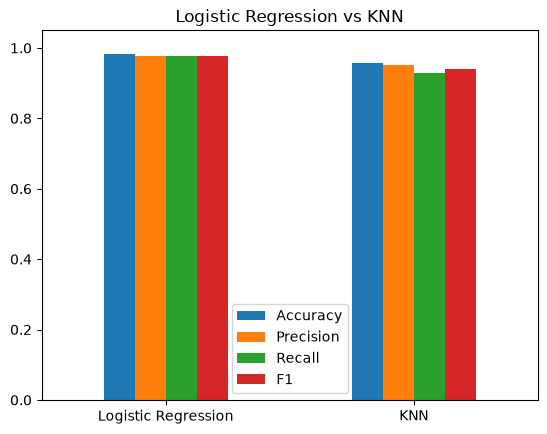

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
models = {'Logistic Regression': Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=2000, random_state=42))]), 'KNN': Pipeline([('scale', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=5))])}
results = {name: evaluate(name, model) for name, model in models.items()}
df = pd.DataFrame(results).T
print(df.round(4))
df.plot.bar(rot=0, ylim=(0, 1.05), title='Logistic Regression vs KNN')


In [5]:
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>